<a href="https://colab.research.google.com/github/akshatsodhi/Skin-Care-and-Cosmetic-Industry-Analysis/blob/main/Skin_Care_and_Cosmetic_Industry_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Demystifying the Beauty Industry**

***Data Description***

The dataset we analyzed was well-structured and required minimal cleaning, allowing us to focus on the analysis. It comprised 15,000 rows and 14 columns, providing comprehensive insights into the beauty industry. The dataset included details such as product names, categories, usage frequency, number of reviews, average ratings, primary ingredients, country of origin, and more.

***Project Description***

The project involves processing and cleaning data to analyze the beauty industry. The diverse set of attributes enabled us to explore key trends, such as identifying top-performing brands and products, analyzing ingredient preferences, and evaluating customer feedback patterns. Furthermore, it allowed us to investigate how factors like a product’s category, frequency of use, and origin influenced its popularity.

***Objective of Analysis***

The objective of this analysis is to get insights into consumer preferences, top countries helping brands prioritize high-demand products and optimize marketing and business strategies for better engagement and sales in the beauty industry.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# from google.colab import files
# uploaded = files.upload()

In [ ]:
file = pd.read_excel('project.xlsx')
file

,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
0,Ultra Face Mask,Drunk Elephant,Blush,Weekly,67.85,1.4,686,30ml,Sensitive,Female,Tube,Retinol,False,Australia
1,Ultra Lipstick,Laura Mercier,Makeup Remover,Occasional,116.43,4.2,5483,250ml,Dry,Unisex,Bottle,Shea Butter,False,UK
2,Ultra Serum,Natasha Denona,Highlighter,Daily,90.84,1.6,5039,100ml,Sensitive,Male,Compact,Aloe Vera,True,Italy
3,Divine Serum,Ilia Beauty,Face Mask,Occasional,55.17,3.2,6202,250ml,Normal,Male,Tube,Glycerin,True,South Korea
4,Super Foundation,Charlotte Tilbury,Highlighter,Occasional,140.56,1.7,297,100ml,Oily,Female,Compact,Glycerin,False,Germany
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,Magic Eyeliner,Patrick Ta,Face Mask,Daily,131.64,2.8,1470,250ml,Sensitive,Unisex,Tube,Aloe Vera,True,Italy
14996,Perfect Powder,Farsali,Serum,Weekly,76.35,2.1,7652,250ml,Dry,Unisex,Jar,Salicylic Acid,True,USA
14997,Magic Serum,Kiehlâ€™s,Highlighter,Occasional,65.37,4.2,811,30ml,Combination,Unisex,Jar,Shea Butter,False,South Korea
14998,Magic Mascara,Perricone MD,Powder,Weekly,59.93,4.8,5482,250ml,Dry,Male,Jar,Aloe Vera,True,USA


# Data Pre-Processing

Inspecting the data to understand the structure

In [ ]:
file.head()  # First 5 rows

,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
0,Ultra Face Mask,Drunk Elephant,Blush,Weekly,67.85,1.4,686,30ml,Sensitive,Female,Tube,Retinol,False,Australia
1,Ultra Lipstick,Laura Mercier,Makeup Remover,Occasional,116.43,4.2,5483,250ml,Dry,Unisex,Bottle,Shea Butter,False,UK
2,Ultra Serum,Natasha Denona,Highlighter,Daily,90.84,1.6,5039,100ml,Sensitive,Male,Compact,Aloe Vera,True,Italy
3,Divine Serum,Ilia Beauty,Face Mask,Occasional,55.17,3.2,6202,250ml,Normal,Male,Tube,Glycerin,True,South Korea
4,Super Foundation,Charlotte Tilbury,Highlighter,Occasional,140.56,1.7,297,100ml,Oily,Female,Compact,Glycerin,False,Germany


In [ ]:
file.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Product_Name       15000 non-null  object 
 1   Brand              15000 non-null  object 
 2   Category           15000 non-null  object 
 3   Usage_Frequency    15000 non-null  object 
 4   Price_USD          15000 non-null  float64
 5   Rating             15000 non-null  float64
 6   Number_of_Reviews  15000 non-null  int64  
 7   Product_Size       15000 non-null  object 
 8   Skin_Type          15000 non-null  object 
 9   Gender_Target      15000 non-null  object 
 10  Packaging_Type     15000 non-null  object 
 11  Main_Ingredient    15000 non-null  object 
 12  Cruelty_Free       15000 non-null  bool   
 13  Country_of_Origin  15000 non-null  object 
dtypes: bool(1), float64(2), int64(1), object(10)
memory usage: 1.5+ MB


In [ ]:
file.describe()

,Price_USD,Rating,Number_of_Reviews
count,15000.000000,15000.000000,15000.000000
mean,80.134108,3.002327,5014.231333
std,40.402983,1.168029,2855.665464
min,10.000000,1.000000,52.000000
25%,45.480000,2.000000,2562.000000
50%,80.040000,3.000000,5002.000000
75%,114.760000,4.000000,7497.000000
max,149.990000,5.000000,10000.000000


In [ ]:
file.columns

Index(['Product_Name', 'Brand', 'Category', 'Usage_Frequency', 'Price_USD',
       'Rating', 'Number_of_Reviews', 'Product_Size', 'Skin_Type',
       'Gender_Target', 'Packaging_Type', 'Main_Ingredient', 'Cruelty_Free',
       'Country_of_Origin'],
      dtype='object')

Check for missing values

In [ ]:
# sum() is used here to add up the 'True' values (representing missing data) in each column after isnull() has identified them
print(file.isnull().sum()) # missing values in each column

Product_Name         0
Brand                0
Category             0
Usage_Frequency      0
Price_USD            0
Rating               0
Number_of_Reviews    0
Product_Size         0
Skin_Type            0
Gender_Target        0
Packaging_Type       0
Main_Ingredient      0
Cruelty_Free         0
Country_of_Origin    0
dtype: int64


The above analysis shows that the data doesn't have any NaN values

Checking for duplicate values

In [ ]:
duplicates = file[file.duplicated()]
duplicates

,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin


This shows that there are no duplicates in this data

<Axes: xlabel='Price_USD'>

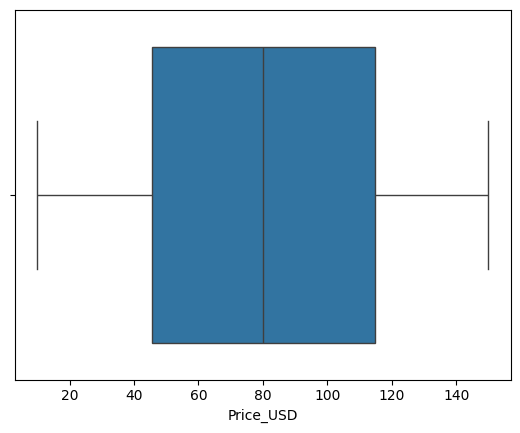

In [ ]:
sns.boxplot(x=file['Price_USD'])  # Boxplot of 'Price_USD'

The above boxplot shows that there are no outliers in the data.

# Data Cleaning

In [ ]:
# removing extra whitespaces at the end
file['Product_Name'] = file['Product_Name'].str.strip()
file['Brand'] = file['Brand'].str.strip()
file

,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
0,Ultra Face Mask,Drunk Elephant,Blush,Weekly,67.85,1.4,686,30ml,Sensitive,Female,Tube,Retinol,False,Australia
1,Ultra Lipstick,Laura Mercier,Makeup Remover,Occasional,116.43,4.2,5483,250ml,Dry,Unisex,Bottle,Shea Butter,False,UK
2,Ultra Serum,Natasha Denona,Highlighter,Daily,90.84,1.6,5039,100ml,Sensitive,Male,Compact,Aloe Vera,True,Italy
3,Divine Serum,Ilia Beauty,Face Mask,Occasional,55.17,3.2,6202,250ml,Normal,Male,Tube,Glycerin,True,South Korea
4,Super Foundation,Charlotte Tilbury,Highlighter,Occasional,140.56,1.7,297,100ml,Oily,Female,Compact,Glycerin,False,Germany
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,Magic Eyeliner,Patrick Ta,Face Mask,Daily,131.64,2.8,1470,250ml,Sensitive,Unisex,Tube,Aloe Vera,True,Italy
14996,Perfect Powder,Farsali,Serum,Weekly,76.35,2.1,7652,250ml,Dry,Unisex,Jar,Salicylic Acid,True,USA
14997,Magic Serum,Kiehlâ€™s,Highlighter,Occasional,65.37,4.2,811,30ml,Combination,Unisex,Jar,Shea Butter,False,South Korea
14998,Magic Mascara,Perricone MD,Powder,Weekly,59.93,4.8,5482,250ml,Dry,Male,Jar,Aloe Vera,True,USA


In [ ]:
# removing special characters in the brand column
file['Brand'] = file['Brand'].str.replace(r'[^a-zA-Z0-9 ]', '', regex=True)
file

,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
0,Ultra Face Mask,Drunk Elephant,Blush,Weekly,67.85,1.4,686,30ml,Sensitive,Female,Tube,Retinol,False,Australia
1,Ultra Lipstick,Laura Mercier,Makeup Remover,Occasional,116.43,4.2,5483,250ml,Dry,Unisex,Bottle,Shea Butter,False,UK
2,Ultra Serum,Natasha Denona,Highlighter,Daily,90.84,1.6,5039,100ml,Sensitive,Male,Compact,Aloe Vera,True,Italy
3,Divine Serum,Ilia Beauty,Face Mask,Occasional,55.17,3.2,6202,250ml,Normal,Male,Tube,Glycerin,True,South Korea
4,Super Foundation,Charlotte Tilbury,Highlighter,Occasional,140.56,1.7,297,100ml,Oily,Female,Compact,Glycerin,False,Germany
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,Magic Eyeliner,Patrick Ta,Face Mask,Daily,131.64,2.8,1470,250ml,Sensitive,Unisex,Tube,Aloe Vera,True,Italy
14996,Perfect Powder,Farsali,Serum,Weekly,76.35,2.1,7652,250ml,Dry,Unisex,Jar,Salicylic Acid,True,USA
14997,Magic Serum,Kiehls,Highlighter,Occasional,65.37,4.2,811,30ml,Combination,Unisex,Jar,Shea Butter,False,South Korea
14998,Magic Mascara,Perricone MD,Powder,Weekly,59.93,4.8,5482,250ml,Dry,Male,Jar,Aloe Vera,True,USA


In [ ]:
# converting 'Product_Size' to string type first, if not already
file['Product_Size'] = file['Product_Size'].astype(str)

# applying the .str.replace method
file['Product_Size'] = file['Product_Size'].str.replace('ml', '', regex=False).astype(float)

file['Product_Size']
file

,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
0,Ultra Face Mask,Drunk Elephant,Blush,Weekly,67.85,1.4,686,30.0,Sensitive,Female,Tube,Retinol,False,Australia
1,Ultra Lipstick,Laura Mercier,Makeup Remover,Occasional,116.43,4.2,5483,250.0,Dry,Unisex,Bottle,Shea Butter,False,UK
2,Ultra Serum,Natasha Denona,Highlighter,Daily,90.84,1.6,5039,100.0,Sensitive,Male,Compact,Aloe Vera,True,Italy
3,Divine Serum,Ilia Beauty,Face Mask,Occasional,55.17,3.2,6202,250.0,Normal,Male,Tube,Glycerin,True,South Korea
4,Super Foundation,Charlotte Tilbury,Highlighter,Occasional,140.56,1.7,297,100.0,Oily,Female,Compact,Glycerin,False,Germany
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,Magic Eyeliner,Patrick Ta,Face Mask,Daily,131.64,2.8,1470,250.0,Sensitive,Unisex,Tube,Aloe Vera,True,Italy
14996,Perfect Powder,Farsali,Serum,Weekly,76.35,2.1,7652,250.0,Dry,Unisex,Jar,Salicylic Acid,True,USA
14997,Magic Serum,Kiehls,Highlighter,Occasional,65.37,4.2,811,30.0,Combination,Unisex,Jar,Shea Butter,False,South Korea
14998,Magic Mascara,Perricone MD,Powder,Weekly,59.93,4.8,5482,250.0,Dry,Male,Jar,Aloe Vera,True,USA


In [ ]:
# ensuring all boolean fields (cruelty_free) are represented consistently
file['Cruelty_Free'] = file['Cruelty_Free'].astype(bool)
file

,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
0,Ultra Face Mask,Drunk Elephant,Blush,Weekly,67.85,1.4,686,30.0,Sensitive,Female,Tube,Retinol,False,Australia
1,Ultra Lipstick,Laura Mercier,Makeup Remover,Occasional,116.43,4.2,5483,250.0,Dry,Unisex,Bottle,Shea Butter,False,UK
2,Ultra Serum,Natasha Denona,Highlighter,Daily,90.84,1.6,5039,100.0,Sensitive,Male,Compact,Aloe Vera,True,Italy
3,Divine Serum,Ilia Beauty,Face Mask,Occasional,55.17,3.2,6202,250.0,Normal,Male,Tube,Glycerin,True,South Korea
4,Super Foundation,Charlotte Tilbury,Highlighter,Occasional,140.56,1.7,297,100.0,Oily,Female,Compact,Glycerin,False,Germany
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,Magic Eyeliner,Patrick Ta,Face Mask,Daily,131.64,2.8,1470,250.0,Sensitive,Unisex,Tube,Aloe Vera,True,Italy
14996,Perfect Powder,Farsali,Serum,Weekly,76.35,2.1,7652,250.0,Dry,Unisex,Jar,Salicylic Acid,True,USA
14997,Magic Serum,Kiehls,Highlighter,Occasional,65.37,4.2,811,30.0,Combination,Unisex,Jar,Shea Butter,False,South Korea
14998,Magic Mascara,Perricone MD,Powder,Weekly,59.93,4.8,5482,250.0,Dry,Male,Jar,Aloe Vera,True,USA


# Analysis and Visualisation

In [ ]:
# TOP BRANDS IN EACH CATEGORY ACCORDING TO RATINGS
cbr = file.groupby(['Category', 'Brand'])['Rating'].mean().reset_index()
topbrands = cbr.loc[cbr.groupby('Category')['Rating'].idxmax()]

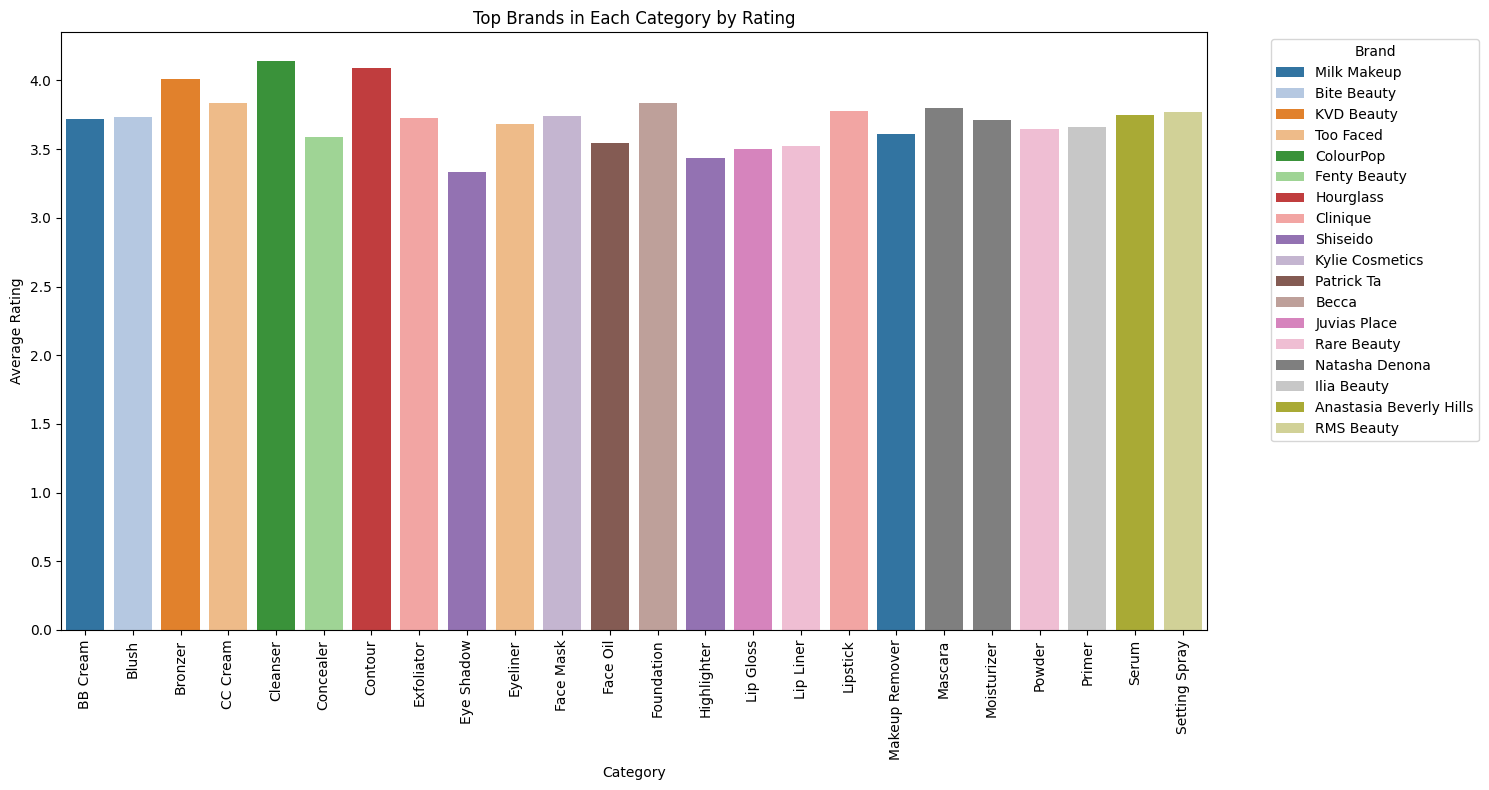

In [ ]:
plt.figure(figsize=(15, 8))
sns.barplot(x='Category', y='Rating', hue='Brand', data=topbrands, palette='tab20')
plt.title('Top Brands in Each Category by Rating')
plt.xlabel('Category')
plt.ylabel('Average Rating')
plt.xticks(rotation=90)
plt.legend(title='Brand', bbox_to_anchor=(1.05,1),  loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# q. Which categories are used most frequently by consumers?
category_usage = file['Category'].value_counts()
category_usage

,count
Category,
Serum,710
Mascara,674
Face Oil,671
Highlighter,653
Face Mask,653
Moisturizer,638
Makeup Remover,636
Lipstick,633
Concealer,633


<ipython-input-69-0ab6c3ef0c2a>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_usage.index, y=category_usage.values, palette='magma')


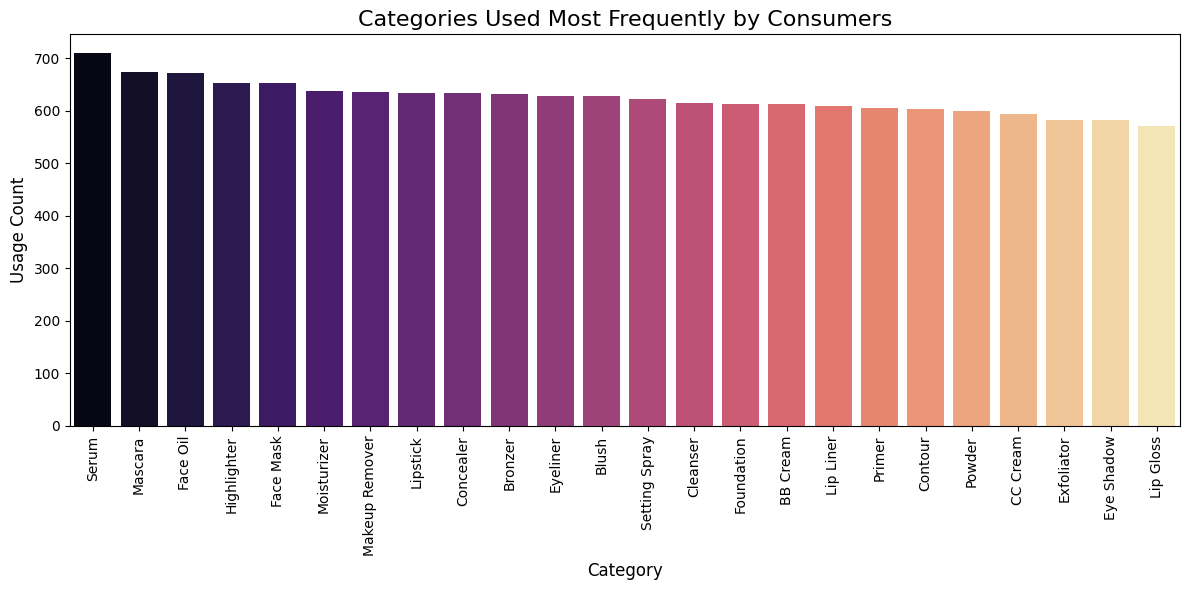

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(x=category_usage.index, y=category_usage.values, palette='magma')
plt.title('Categories Used Most Frequently by Consumers', fontsize=16)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Usage Count', fontsize=12)
plt.xticks(rotation=90, fontsize=10)
plt.tight_layout()
plt.show()

The above bar chart shows that :


*   Most frequently used product - SERUM
*   Least frequently used product - LIP GLOSS



([<matplotlib.patches.Wedge at 0x7d3ef2ada350>,
 [Text(-1.0413601746178986, 0.59629605626717, 'Male'),
  Text(0.008293763428091723, -1.0999687329593506, 'Female'),
  Text(0.9504317445041621, 0.5537865103438103, 'Unisex')],
 [Text(-0.6074601018604407, 0.3478393661558491, '33.4%'),
  Text(0.004523870960777303, -0.5999829452505547, '33.3%'),
  Text(0.5184173151840884, 0.30206536927844196, '33.2%')])

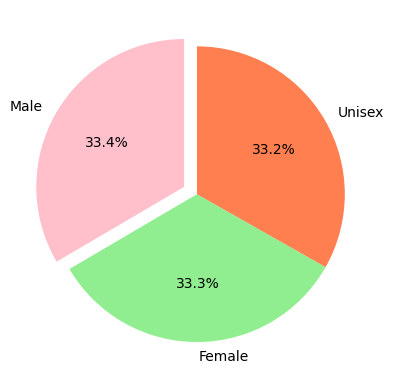

In [ ]:
# WHICH GENDERS ARE TARGETED MORE
gendertarget = file['Gender_Target'].value_counts()
gendertarget
explode = (0.1, 0, 0)
g_label = ["Male","Female","Unisex"]
colors = ['pink',  'lightgreen', 'coral']
plt.pie(gendertarget, labels = g_label, autopct='%1.1f%%', startangle=90, colors = colors, explode = explode)

The pie chart shows that Men are targeted the most but men and women are targeted almost equally.

In [ ]:
# Country of origin
country = file['Country_of_Origin'].value_counts()
country

,count
Country_of_Origin,
Italy,1942
USA,1931
Australia,1873
France,1863
Japan,1861
South Korea,1851
UK,1846
Germany,1833


<ipython-input-72-43bb89e5aac3>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=country.index, x=country.values, orient='h', palette='rocket')


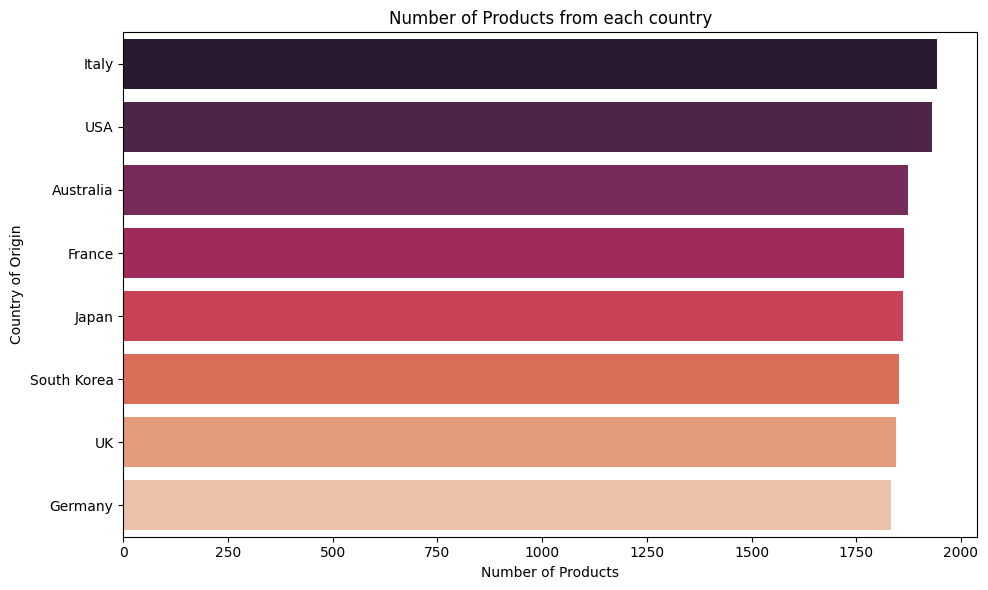

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(y=country.index, x=country.values, orient='h', palette='rocket')
plt.title('Number of Products from each country')
plt.xlabel('Number of Products')
plt.ylabel('Country of Origin')
plt.tight_layout()
plt.show()

The above chart shows that Italy is the country with the highest number of products.

In [ ]:
# Top brands
brand_ratings = file.groupby('Brand')['Rating'].mean()
brand_ratings

,Rating
Brand,
Anastasia Beverly Hills,3.052846
Becca,3.100000
Bite Beauty,3.065816
Bobby Brown,2.966579
Bourjois,2.943417
Charlotte Tilbury,3.000275
Clinique,2.914854
ColourPop,3.039024
Danessa Myricks,2.958939


<ipython-input-74-0e9d0c81acb7>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=brand_ratings.index, y=brand_ratings.values, palette='viridis')


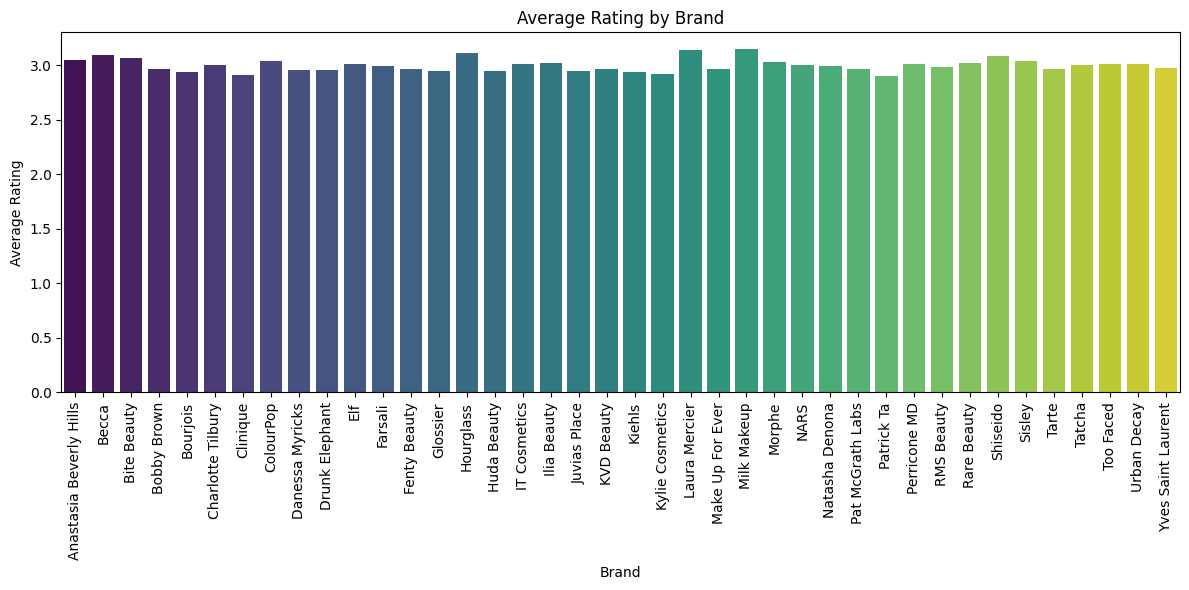

In [ ]:
plt.figure(figsize=(12, 6))  # Adjust figure size as needed
sns.barplot(x=brand_ratings.index, y=brand_ratings.values, palette='viridis')
plt.title('Average Rating by Brand')
plt.xlabel('Brand')
plt.ylabel('Average Rating')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
#Are cruelty-free products rated higher than non-cruelty product?
mean_ratings = file.groupby('Cruelty_Free')['Rating'].mean()
print("Mean Ratings for Cruelty-Free vs Non-Cruelty-Free:")
print(mean_ratings)




Mean Ratings for Cruelty-Free vs Non-Cruelty-Free:
Cruelty_Free
False    2.999065
True     3.005670
Name: Rating, dtype: float64


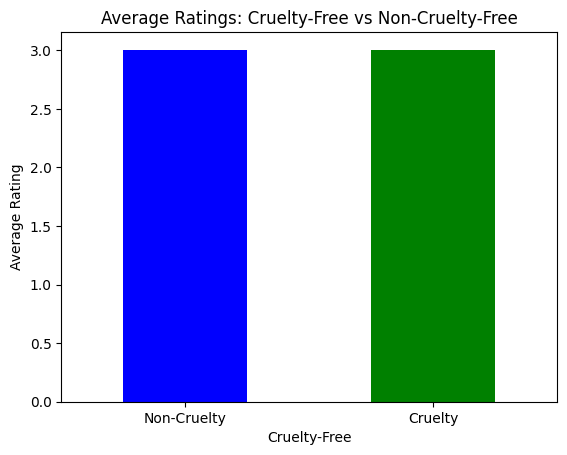

In [ ]:
mean_ratings.plot(kind='bar', color=['blue', 'green'])
plt.title("Average Ratings: Cruelty-Free vs Non-Cruelty-Free")
plt.xticks([0, 1], ['Non-Cruelty','Cruelty'])
plt.xlabel('Cruelty-Free')
plt.ylabel('Average Rating')
plt.xticks(rotation=0)
plt.show()


In [ ]:
#Which skin types are most catered to by the listed products?
skin_type_distribution = file['Skin_Type'].value_counts()
skin_type_distribution



,count
Skin_Type,
Combination,3060
Oily,3009
Normal,2991
Sensitive,2975
Dry,2965


<ipython-input-78-4777094660a7>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Skin_Type', data=file, order=skin_type_distribution.index, palette='coolwarm')


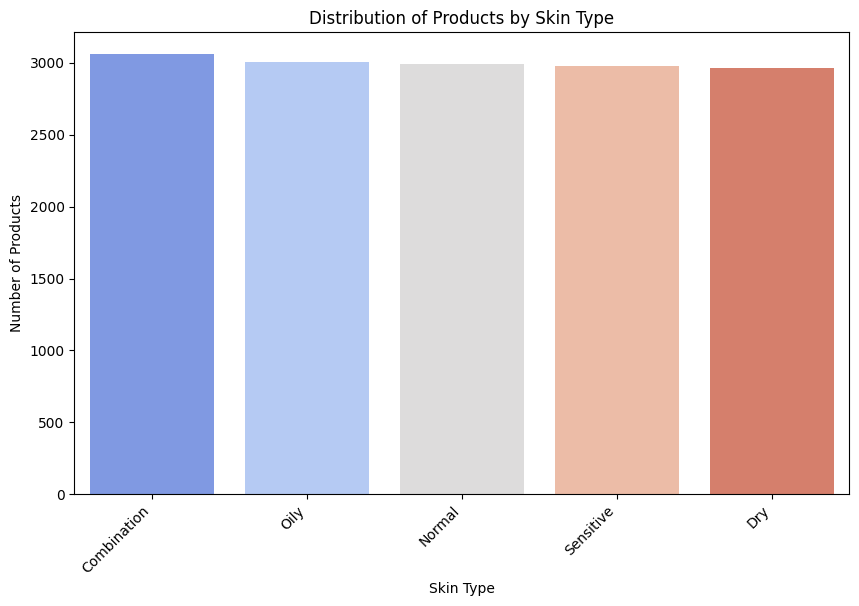

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(x='Skin_Type', data=file, order=skin_type_distribution.index, palette='coolwarm')
plt.title('Distribution of Products by Skin Type')
plt.xlabel('Skin Type')
plt.ylabel('Number of Products')
plt.xticks(rotation=45, ha='right')
plt.show()


In [ ]:
#What are the most common packaging types, and do they impact product ratings?
packaging_distribution = file['Packaging_Type'].value_counts()
average_ratings_by_packaging = file.groupby('Packaging_Type')['Rating'].mean().sort_values(ascending=False)
packaging_distribution


,count
Packaging_Type,
Jar,2567
Bottle,2532
Stick,2529
Spray,2528
Compact,2454
Tube,2390


<ipython-input-80-6d1ca9f9052f>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Packaging_Type', data=file, order=packaging_distribution.index,palette='cubehelix')


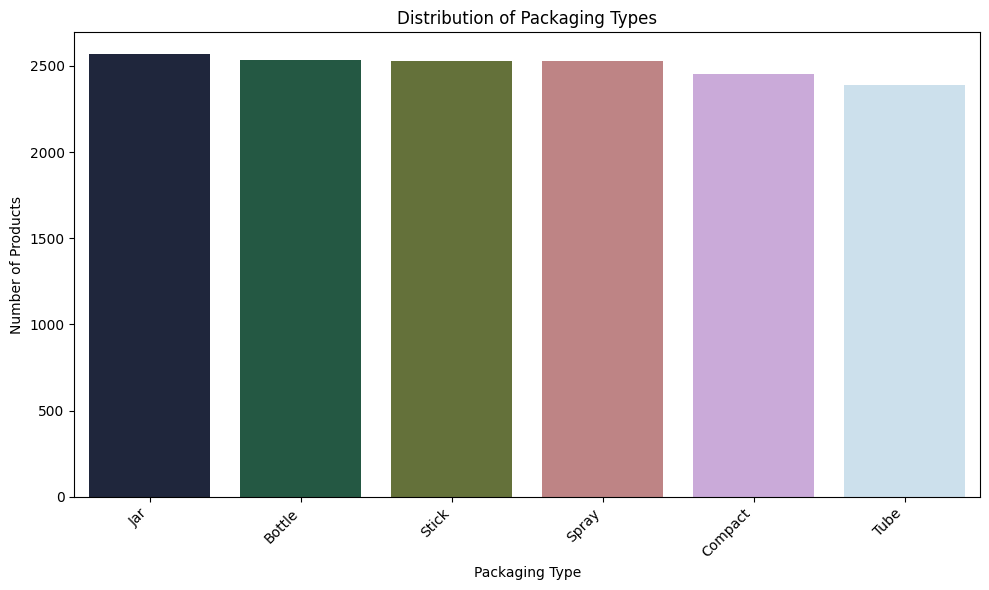

In [ ]:
#packaging distribution
plt.figure(figsize=(10, 6))
sns.countplot(x='Packaging_Type', data=file, order=packaging_distribution.index,palette='cubehelix')
plt.title('Distribution of Packaging Types')
plt.xlabel('Packaging Type')
plt.ylabel('Number of Products')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


Packaging_Type
Jar        3.018465
Stick      3.013009
Tube       3.011548
Bottle     3.009518
Spray      2.984098
Compact    2.976813
Name: Rating, dtype: float64


<ipython-input-81-18e1c32675d7>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=average_ratings_by_packaging.index, y=average_ratings_by_packaging.values, palette='crest')


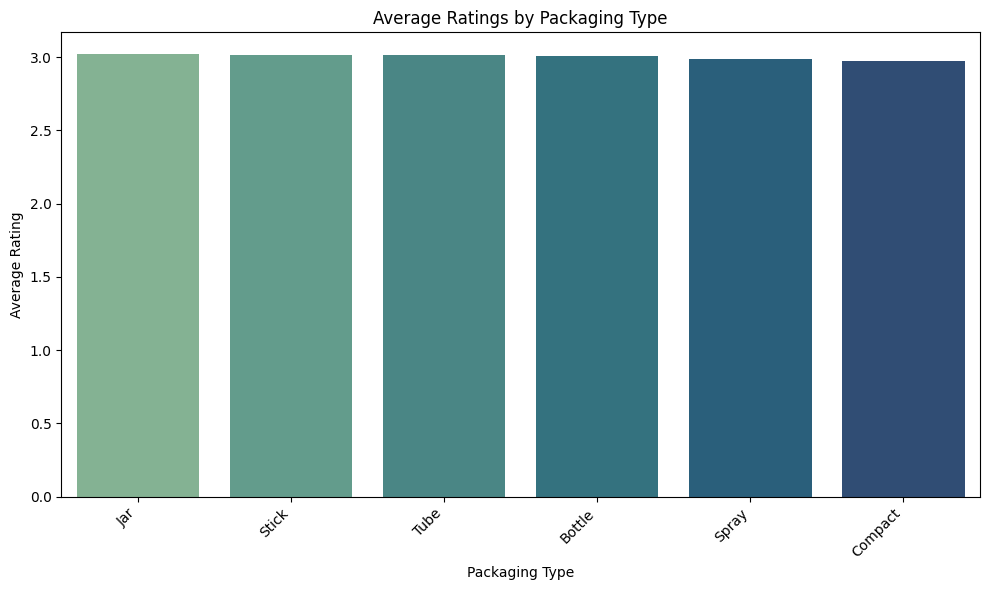

In [ ]:
#bar plot for average ratings by packaging type
print(average_ratings_by_packaging)
plt.figure(figsize=(10, 6))
sns.barplot(x=average_ratings_by_packaging.index, y=average_ratings_by_packaging.values, palette='crest')
plt.title('Average Ratings by Packaging Type')
plt.xlabel('Packaging Type')
plt.ylabel('Average Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**8. How does the packaging type influence product ratings and reviews?**

In [ ]:
packaging_analysis = file.groupby('Packaging_Type')[['Number_of_Reviews']].mean()
packaging_analysis

,Number_of_Reviews
Packaging_Type,
Bottle,5008.255529
Compact,4987.878973
Jar,4968.772497
Spray,5118.641218
Stick,4963.333729
Tube,5039.864854


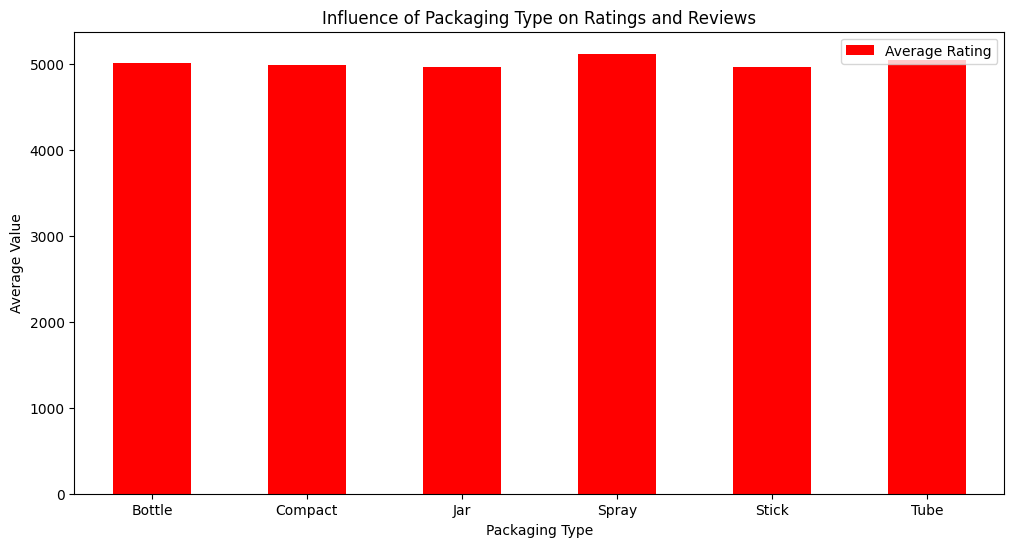

In [ ]:
# Clustered bar chart for packaging type
packaging_analysis.plot(kind='bar', figsize=(12, 6), color=['red'])
plt.xlabel('Packaging Type')
plt.ylabel('Average Value')
plt.title('Influence of Packaging Type on Ratings and Reviews')
plt.legend(['Average Rating', 'Average Reviews'])
plt.xticks(rotation=360)
plt.show()

**10  Are there any trends let's discuss it with different different attributes:**

*a. Trend Analysis by Brand*

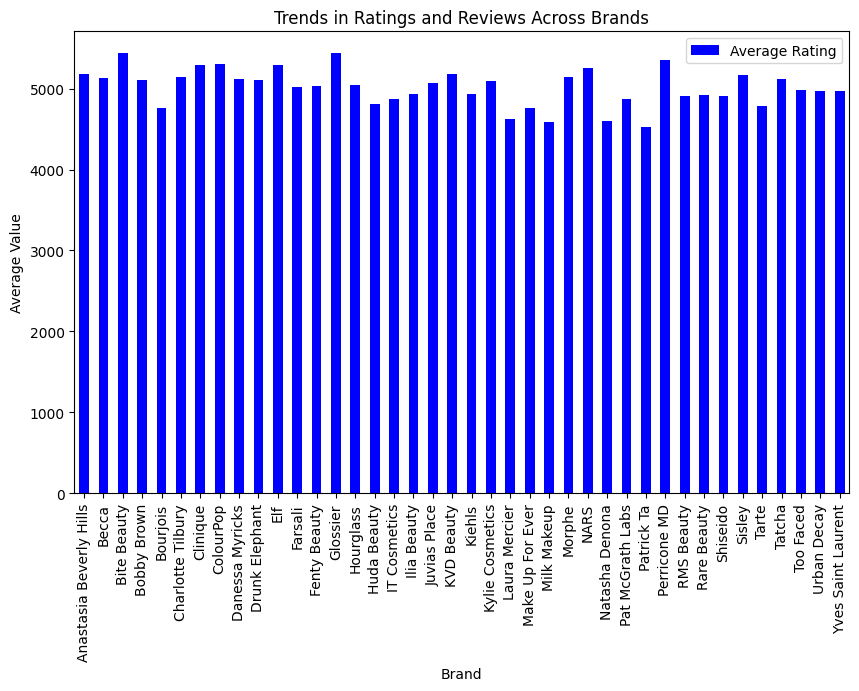

,Number_of_Reviews
Brand,
Anastasia Beverly Hills,5175.0
Becca,5128.5
Bite Beauty,5435.0
Bobby Brown,5105.5
Bourjois,4762.0
Charlotte Tilbury,5142.5
Clinique,5289.0
ColourPop,5303.0
Danessa Myricks,5122.0


In [ ]:
brand_trend = file.groupby('Brand')[['Number_of_Reviews']].median()
brand_trend.plot(kind='bar', figsize=(10,6), color=['blue'])
plt.xlabel('Brand')
plt.ylabel('Average Value')
plt.title('Trends in Ratings and Reviews Across Brands')
plt.xticks(rotation=90)
plt.legend(['Average Rating', 'Average Reviews'])
plt.show()
brand_trend


*b. Trend Analysis by Category*

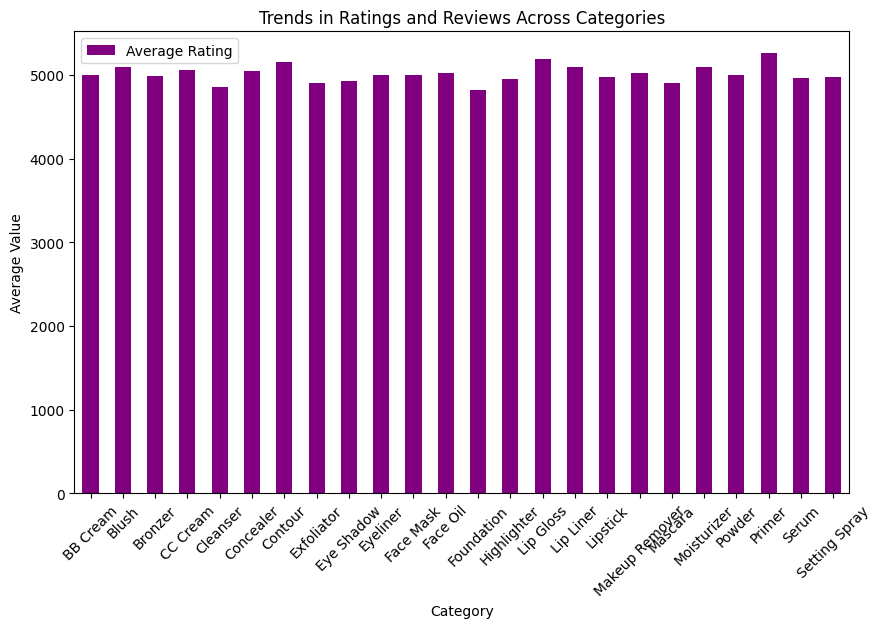

,Number_of_Reviews
Category,
BB Cream,4995.306688
Blush,5091.850318
Bronzer,4990.641838
CC Cream,5062.173401
Cleanser,4861.343648
Concealer,5046.052133
Contour,5156.783113
Exfoliator,4906.782161
Eye Shadow,4934.900344


In [ ]:
category_trend = file.groupby('Category')[[ 'Number_of_Reviews']].mean()
category_trend.plot(kind='bar', figsize=(10,6), color=[ 'purple'])
plt.xlabel('Category')
plt.ylabel('Average Value')
plt.title('Trends in Ratings and Reviews Across Categories')
plt.legend(['Average Rating', 'Average Reviews'])
plt.xticks(rotation=45)
plt.show()
category_trend

*c. trend analysis by price_usd*

In [ ]:
price_buckets = pd.cut(file['Price_USD'], bins=[0, 20, 50, 100, 500], labels=['Low', 'Medium', 'High', 'Premium'])
price_trend = file.groupby(price_buckets)[['Number_of_Reviews']].mean()
price_trend

<ipython-input-86-4f4d9e517776>:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  price_trend = file.groupby(price_buckets)[['Number_of_Reviews']].mean()


,Number_of_Reviews
Price_USD,
Low,4884.750977
Medium,5035.533862
High,5043.689623
Premium,4996.934050


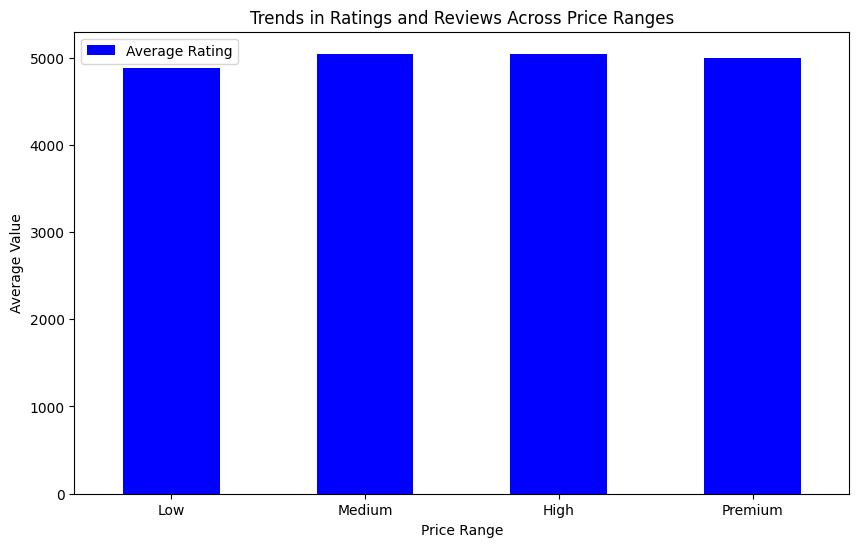

In [ ]:
price_trend.plot(kind='bar', figsize=(10, 6), color=['blue'])
plt.xlabel('Price Range')
plt.ylabel('Average Value')
plt.title('Trends in Ratings and Reviews Across Price Ranges')
plt.legend(['Average Rating', 'Average Reviews'])
plt.xticks(rotation=360)
plt.show()




*c. Identifying Popular Ingredients in Top-Rated Products*

In [ ]:
top_rated_products = file[file['Rating'] >= 4.5]  # Assuming 4.5+ is top-rated
ingredient_counts = top_rated_products['Main_Ingredient'].value_counts()
print(ingredient_counts)


Main_Ingredient
Shea Butter        345
Retinol            325
Glycerin           320
Hyaluronic Acid    313
Salicylic Acid     301
Aloe Vera          296
Vitamin C          288
Name: count, dtype: int64


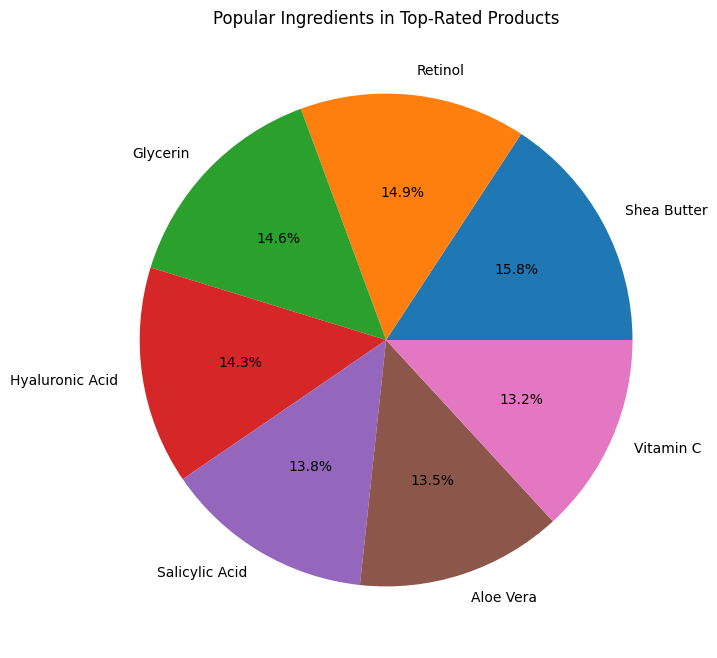

In [ ]:
# Pie Chart
ingredient_counts.plot(kind='pie', figsize=(8, 8), autopct='%1.1f%%')
plt.ylabel('')  # To remove the y-axis label
plt.title('Popular Ingredients in Top-Rated Products')
plt.show()

*d. trend analysis by skin type*

In [ ]:
avg_rating_by_skin_type = file.groupby('Skin_Type')[['Rating']].mean()
avg_rating_by_skin_type

,Rating
Skin_Type,
Combination,3.007974
Dry,3.002057
Normal,3.017920
Oily,2.988269
Sensitive,2.995328


<Axes: title={'center': 'Average Rating by Skin Type'}, xlabel='Skin Type', ylabel='Average Rating'>

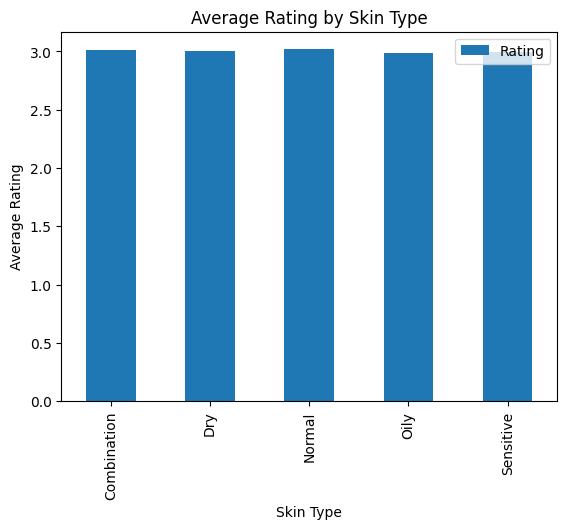

In [ ]:
#   Average Rating Trends by Skin Type

avg_rating_by_skin_type.plot(kind='bar', title='Average Rating by Skin Type', xlabel='Skin Type', ylabel='Average Rating')

*e. trend analysis by gender*

In [ ]:
# Calculate mean ratings and reviews by gender target
gender_trend = file.groupby('Gender_Target')[['Rating', 'Number_of_Reviews']].mean()
gender_trend


,Rating,Number_of_Reviews
Gender_Target,,
Female,2.998001,5051.626749
Male,3.022723,5051.453060
Unisex,2.986127,4939.187513


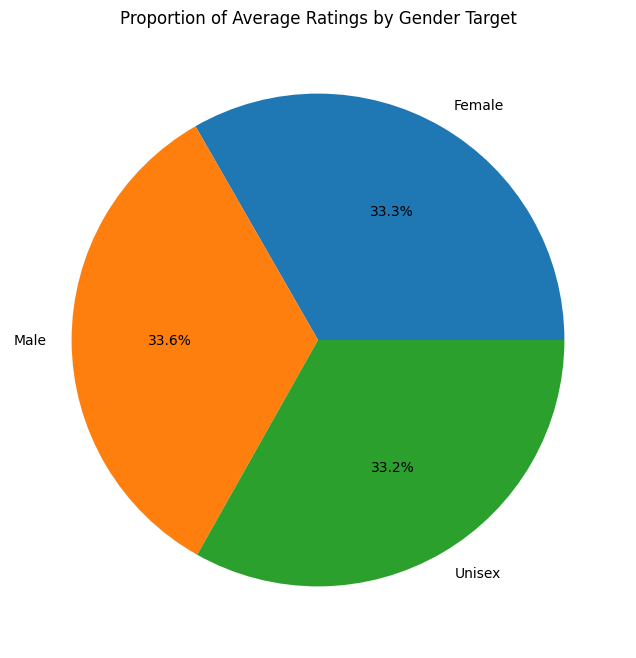

In [ ]:
# Pie chart for Average Ratings
plt.figure(figsize=(8, 8))
plt.pie(
    gender_trend['Rating'],
    labels=gender_trend.index,
    autopct='%1.1f%%',
)
plt.title('Proportion of Average Ratings by Gender Target')
plt.show()


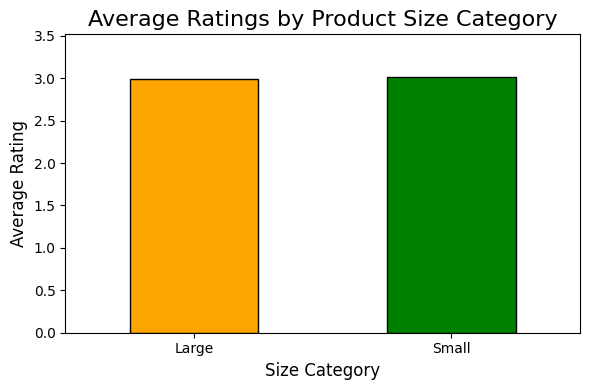

In [ ]:
#7)	Are larger-sized products rated higher than smaller-sized ones?
# Convert 'Product_Size' to string type before using .str accessor if it's not already string type
file['Product_Size'] = file['Product_Size'].astype(str)
file['Product_Size'] = file['Product_Size'].str.extract(r'(\d+)').astype(float)

median_size = file['Product_Size'].median()
file['Size_Category'] = ['Large' if size >= median_size else 'Small' for size in file['Product_Size']]

size_ratings = file.groupby('Size_Category')['Rating'].mean()

median_size, size_ratings

plt.figure(figsize=(6, 4))
size_ratings.plot(kind='bar', color=['orange', 'green'], edgecolor='black')

plt.title("Average Ratings by Product Size Category", fontsize=16)
plt.xlabel("Size Category", fontsize=12)
plt.ylabel("Average Rating", fontsize=12)
plt.xticks(rotation=0, fontsize=10)
plt.ylim(0, size_ratings.max() + 0.5)

plt.tight_layout()
plt.show()